In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.colors as mcolors

from joblib import dump, load

from sklearn.decomposition import PCA
import umap

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def plot_freq(data:pd.DataFrame, title:str, mode='series', bins=32):

    if mode == 'series':
        arr = data
    if mode == 'genes':
        arr = data.mean()
    if mode == 'samples':
        arr = data.T.mean()
    if mode == 'entries':
        arr = data.stack()

    sns.histplot(arr, kde=True, bins=bins, color='dodgerblue', edgecolor=None)
    
    plt.xlabel(title)
    plt.ylabel('frequency')

    plt.show()

In [3]:
transcriptomics = load('data/transcriptomics_processed.joblib')
proteomics = load('data/proteomics_processed.joblib')

## Matching samples and reindexing

In [4]:
indices = [idx for idx in proteomics.index if idx in transcriptomics.index]
len(indices)

369

In [5]:
transcriptomics = transcriptomics.reindex(indices)
proteomics = proteomics.reindex(indices)

In [6]:
transcriptomics.shape, proteomics.shape

((369, 51989), (369, 7372))

## NaNs removal

In [7]:
(transcriptomics.T.isna().sum() != 0).sum(), transcriptomics.isna().sum().sum()

# no nans

(0, 0)

In [8]:
(proteomics.isna().sum() != 0).sum()

# 2259 columns out of 7372 contain nans

2259

In [9]:
proteomics.dropna(axis=1, inplace=True)

In [10]:
transcriptomics.shape, proteomics.shape

((369, 51989), (369, 5113))

## Explorative plots

In [11]:
(transcriptomics == 0).sum().sum() / (transcriptomics.shape[0] * transcriptomics.shape[1])

# around half of the entries are 0

0.47357167122229993

In [12]:
(transcriptomics ** 2).mean()

A1BG        12.185834
A1BG-AS1     5.088746
A1CF         1.063242
A2M          4.034295
A2M-AS1      0.242662
              ...    
ZYG11AP1     0.030074
ZYG11B       7.084674
ZYX         39.500006
ZZEF1       12.881894
ZZZ3        19.566464
Length: 51989, dtype: float64

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


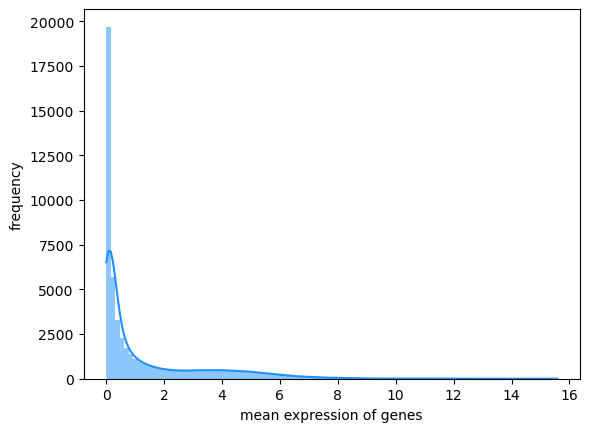

In [13]:
plot_freq((transcriptomics ** 2).mean() ** 0.5,
          title='mean expression of genes', bins=100)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


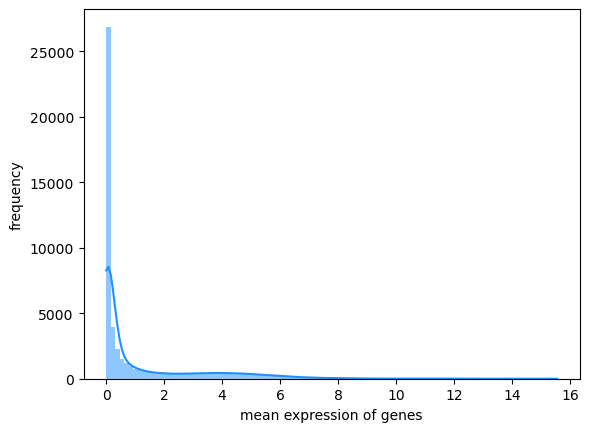

In [14]:
plot_freq(transcriptomics.mean(),
          title='mean expression of genes', bins=100)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


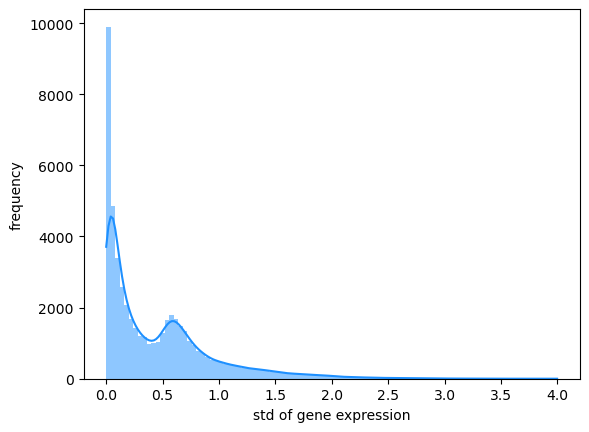

In [15]:
plot_freq(transcriptomics.std(),
          title='std of gene expression', bins=100)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


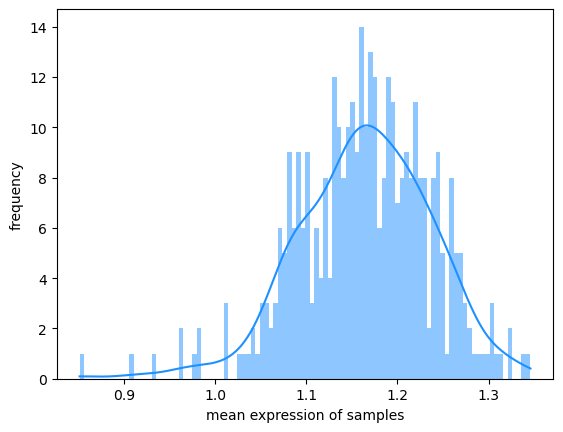

In [16]:
plot_freq(transcriptomics.T.mean(),
          title='mean expression of samples', bins=100)

In [17]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(transcriptomics.T)

pca_df = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])

In [18]:
umap_model = umap.UMAP(n_components=2)
umap_result = umap_model.fit_transform(transcriptomics.T)

umap_df = pd.DataFrame(data=umap_result, columns=['UMAP1', 'UMAP2'])

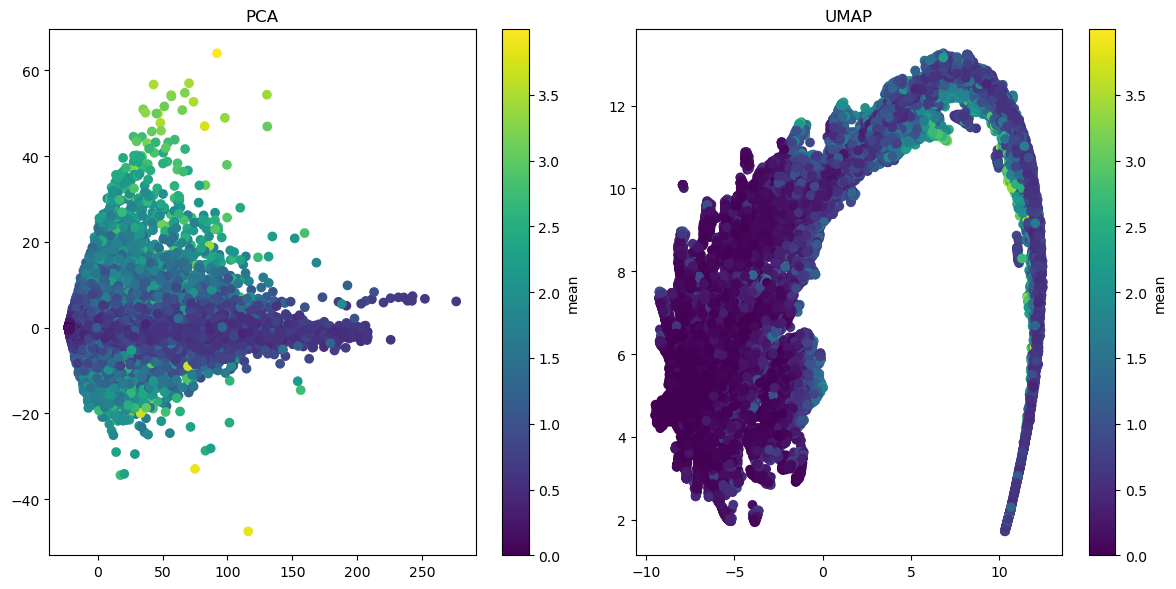

In [19]:
from matplotlib import cm
import matplotlib.colors as mcolors

values = (transcriptomics != 0).sum()
values = transcriptomics.std()

norm = mcolors.Normalize(vmin=np.min(values), vmax=np.max(values))
cmap = cm.viridis

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
scatter = plt.scatter(pca_df['PC1'], pca_df['PC2'], c=values, cmap=cmap, norm=norm)
plt.title('PCA')
plt.colorbar(scatter, label='mean')

plt.subplot(1, 2, 2)
scatter = plt.scatter(umap_df['UMAP1'], umap_df['UMAP2'], c=values, cmap=cmap, norm=norm)
plt.title('UMAP')
plt.colorbar(scatter, label='mean')

plt.tight_layout()
plt.show()

In [20]:
m = len(transcriptomics)
n = len(transcriptomics.T)
m, n

(369, 51989)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


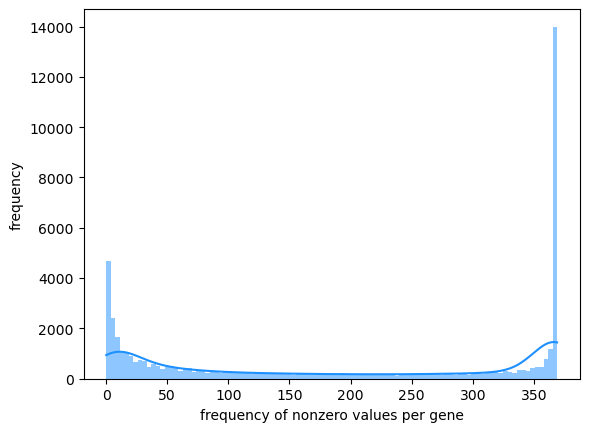

In [21]:
plot_freq((transcriptomics != 0).sum(),
          title='frequency of nonzero values per gene', bins=100)

C:\Users\ccald\AppData\Local\Temp\ipykernel_12372\1981201996.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(transcriptomics.mean(), shade=True)
c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


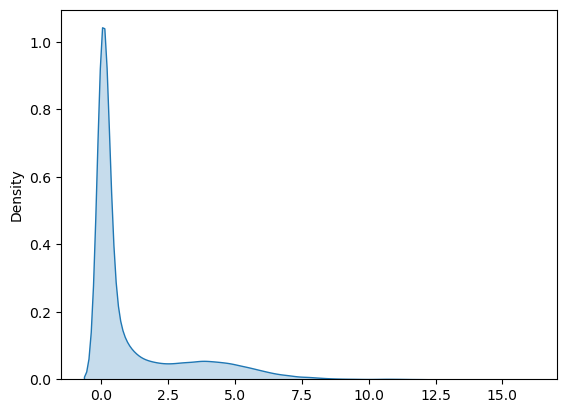

In [22]:
sns.kdeplot(transcriptomics.mean(), shade=True)
plt.show()

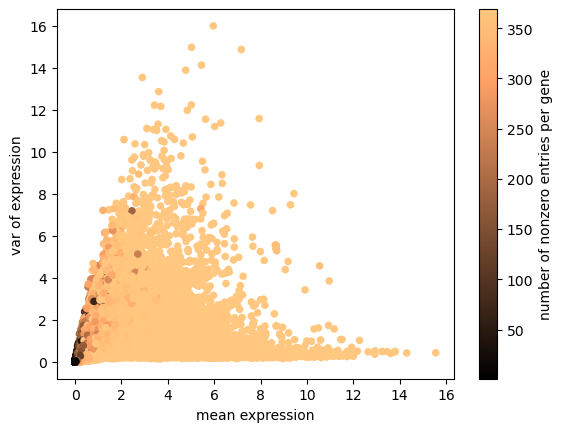

In [23]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.var()[transcriptomics.std() > t]
z = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

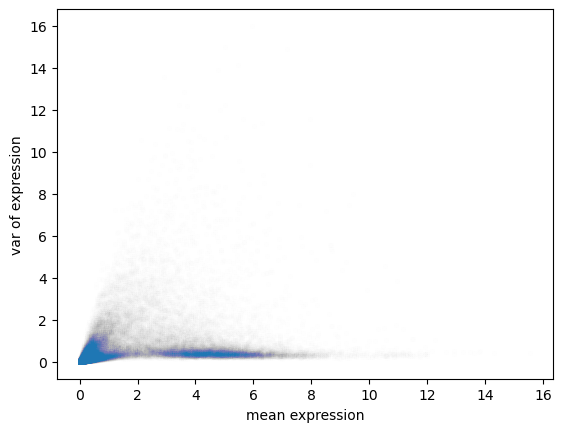

In [24]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.var()[transcriptomics.std() > t]
z = (transcriptomics != 0).sum()[transcriptomics.std() > t]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

- Reducing the opacity of dots we can see that most genes belong to one of two dense areas
- The dense area on the left is unexpressed, the one on the right is expressed
- The left peak cannot be removed by filtering out low variable genes, as the right peak would also disappear

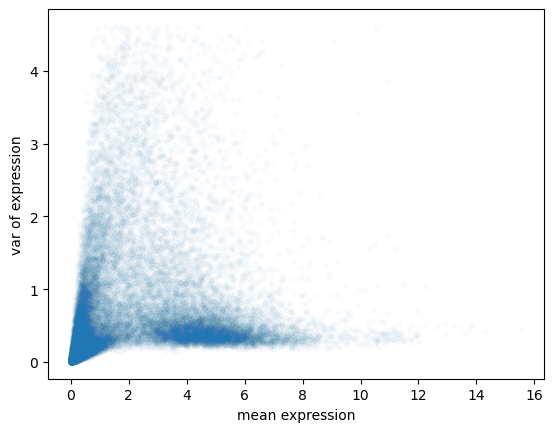

In [25]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)
u = transcriptomics.std().quantile(0.99)

x = transcriptomics.mean()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
y = transcriptomics.var()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
z = (transcriptomics != 0).sum()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.02)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

In [26]:
len(transcriptomics.mean()[(transcriptomics.mean() >= 2) | (transcriptomics.var() >= 1)])

14590

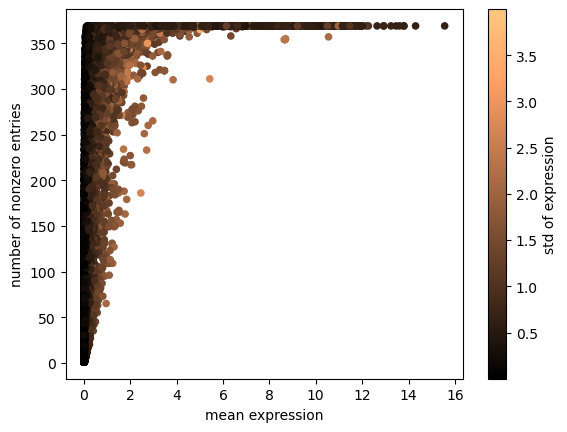

In [27]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
z = transcriptomics.std()[transcriptomics.std() > t]
y = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

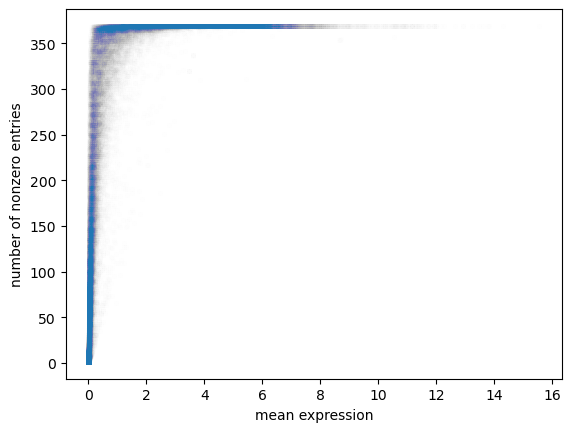

In [28]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
z = transcriptomics.std()[transcriptomics.std() > t]
y = (transcriptomics != 0).sum()[transcriptomics.std() > t]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

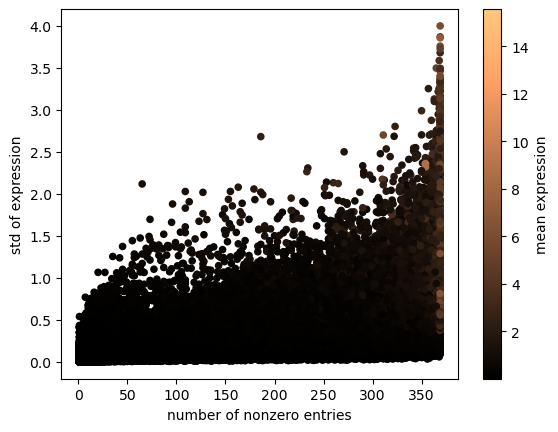

In [29]:
t = transcriptomics.std().quantile(0)

z = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.std()[transcriptomics.std() > t]
x = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

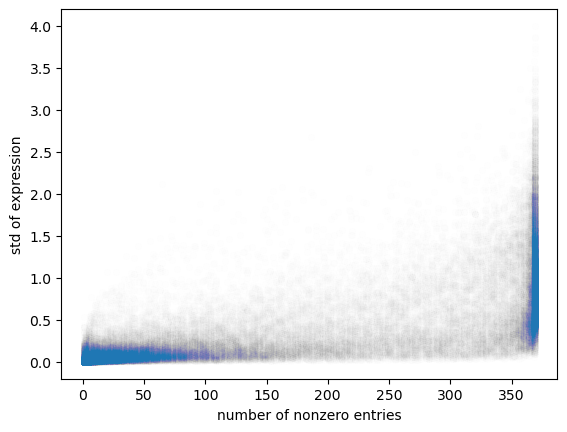

In [30]:
t = transcriptomics.std().quantile(0)

z = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.std()[transcriptomics.std() > t]
x = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, s=20, alpha=0.005)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

## Filtered plots

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


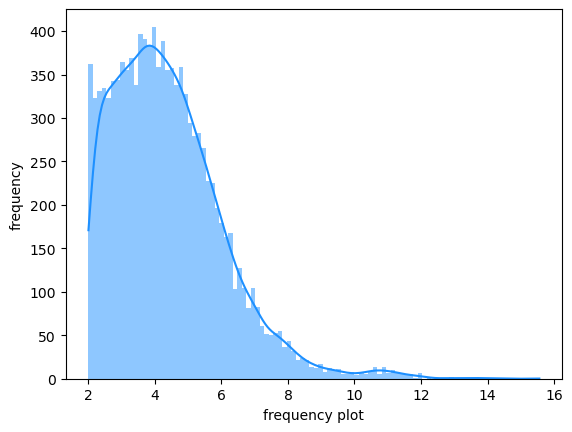

In [31]:
plot_freq(transcriptomics.mean()[transcriptomics.mean() > 2],
          title='frequency plot', bins=100)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


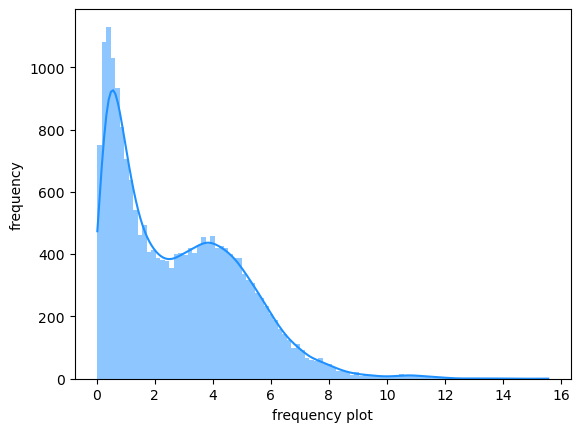

In [32]:
plot_freq(transcriptomics.mean()[(transcriptomics != 0).sum() > 300],
          title='frequency plot', bins=100)

### Mean expression filtering

In [33]:
transcriptomics.shape

(369, 51989)

In [34]:
11400/51989

0.2192771547827425

In [35]:
transcriptomics_mean_filtered = transcriptomics.T[transcriptomics.mean() > 2].T
transcriptomics_mean_filtered.shape

(369, 11400)

In [36]:
transcriptomics_mean_filtered.shape

(369, 11400)

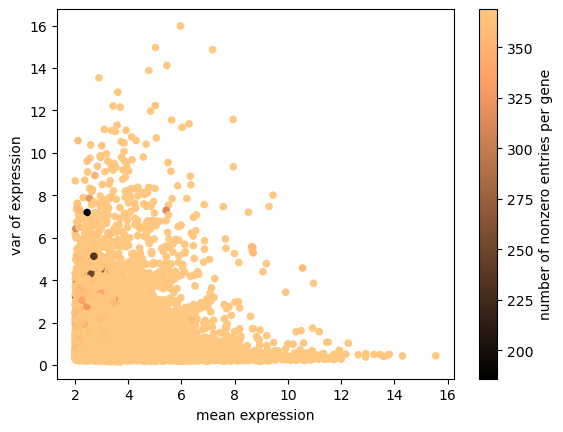

In [37]:
x = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.var()
z = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

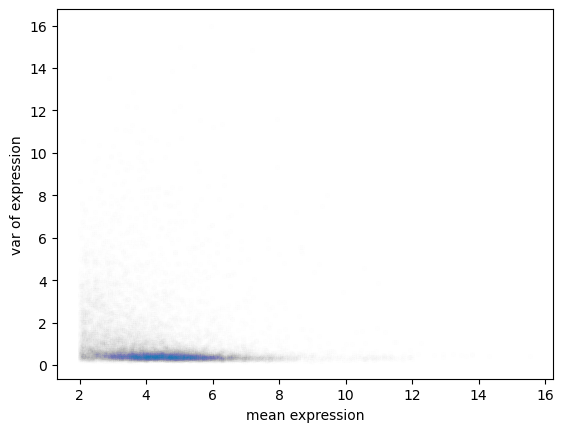

In [38]:
x = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.var()
z = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

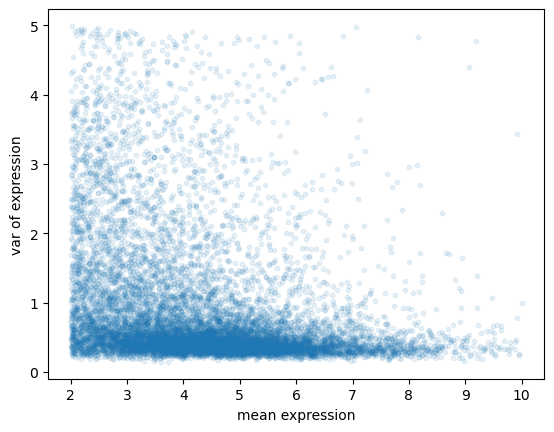

In [39]:
# zoommed plot

x = transcriptomics_mean_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_mean_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.1)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

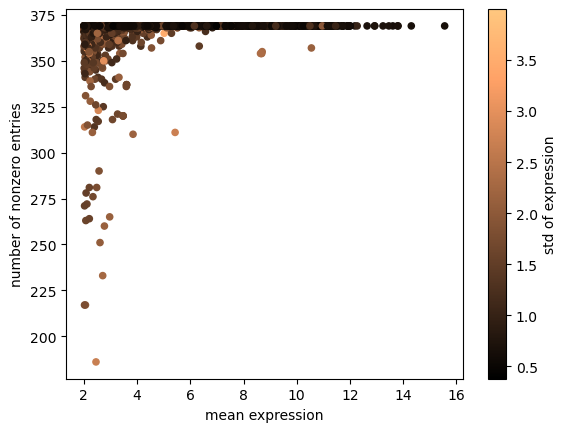

In [40]:
x = transcriptomics_mean_filtered.mean()
z = transcriptomics_mean_filtered.std()
y = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

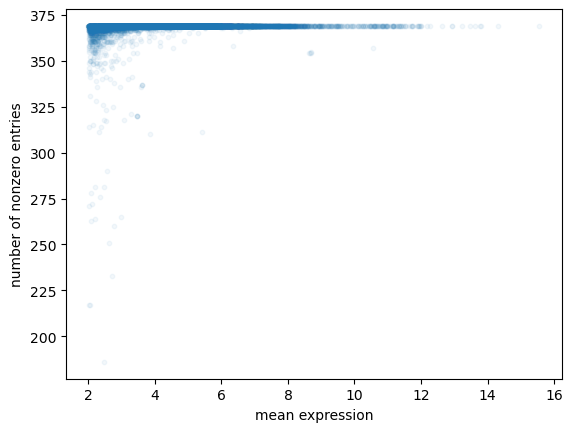

In [41]:
x = transcriptomics_mean_filtered.mean()
z = transcriptomics_mean_filtered.var()
y = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

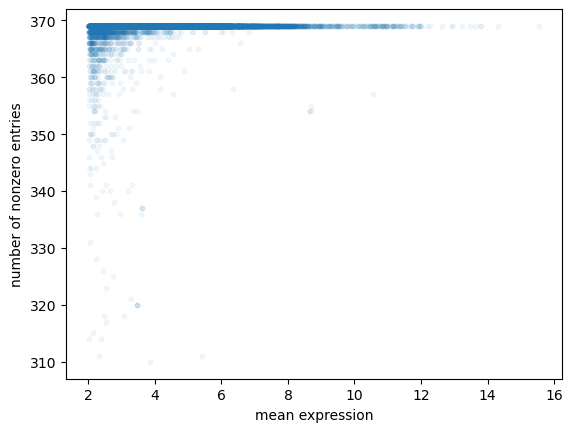

In [42]:
# zoommed

x = transcriptomics_mean_filtered.mean()[(transcriptomics_mean_filtered != 0).sum() > 300]
z = transcriptomics_mean_filtered.var()[(transcriptomics_mean_filtered != 0).sum() > 300]
y = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics_mean_filtered != 0).sum() > 300]

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

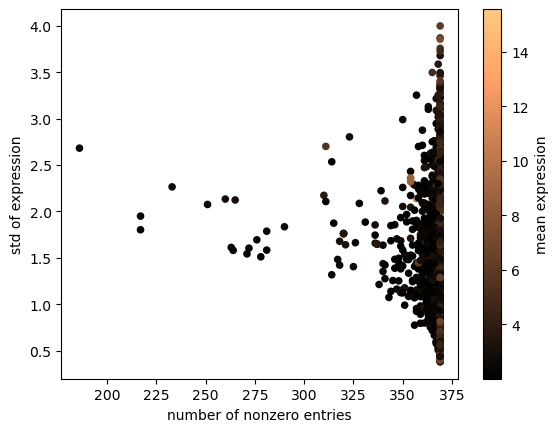

In [43]:
z = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.std()
x = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

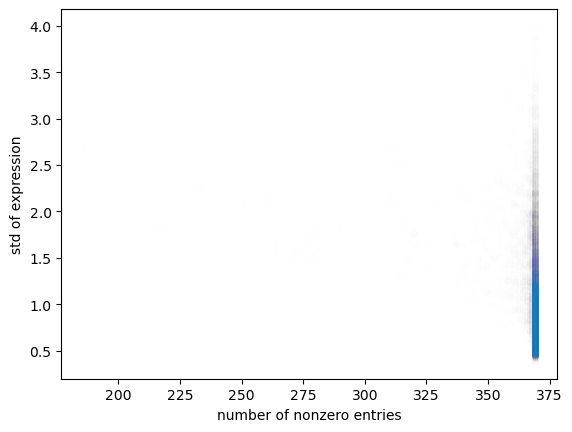

In [44]:
z = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.std()
x = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=20, alpha=0.005)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

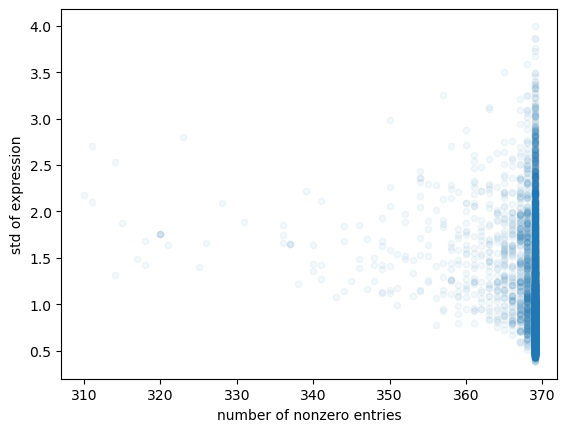

In [45]:
# zoommed

z = transcriptomics_mean_filtered.mean()[(transcriptomics_mean_filtered != 0).sum() > 300]
y = transcriptomics_mean_filtered.std()[(transcriptomics_mean_filtered != 0).sum() > 300]
x = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics_mean_filtered != 0).sum() > 300]

plt.scatter(x, y, s=20, alpha=0.05)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

### Non-zeros count filtering

In [46]:
transcriptomics_nonzero_filtered = transcriptomics.T[(transcriptomics != 0).sum() > 300].T

In [47]:
transcriptomics_nonzero_filtered.shape

(369, 20653)

In [48]:
20653/51989

0.39725711208140185

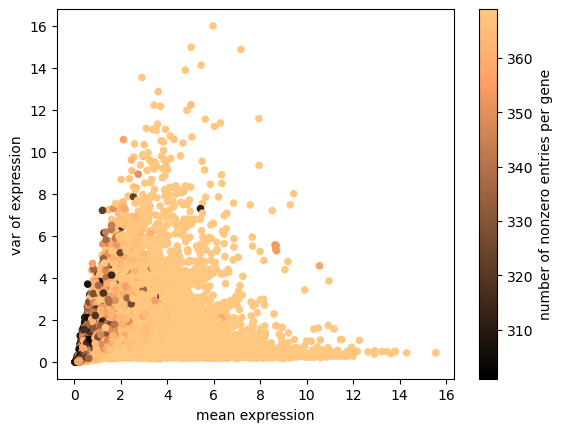

In [49]:
x = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.var()
z = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

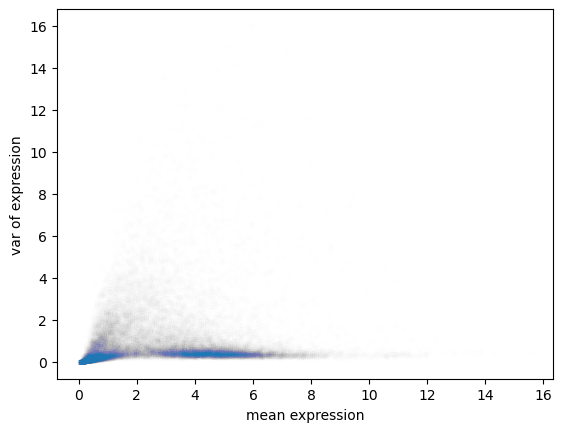

In [50]:
x = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.var()
z = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

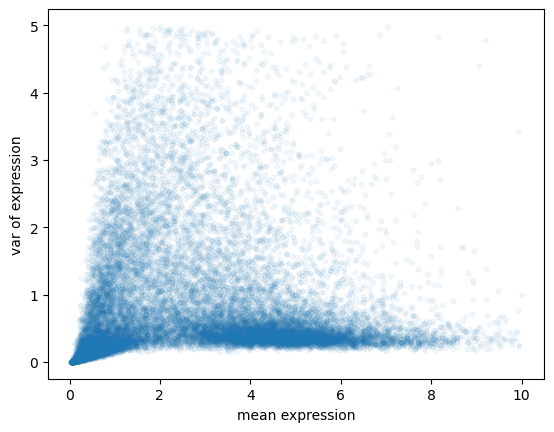

In [51]:
# zoommed plot

x = transcriptomics_nonzero_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_nonzero_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_nonzero_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

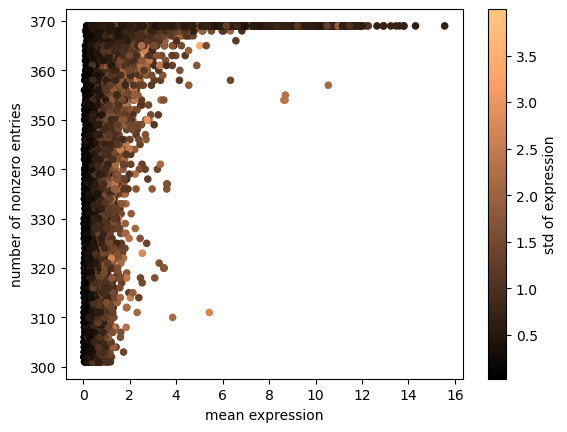

In [52]:
x = transcriptomics_nonzero_filtered.mean()
z = transcriptomics_nonzero_filtered.std()
y = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

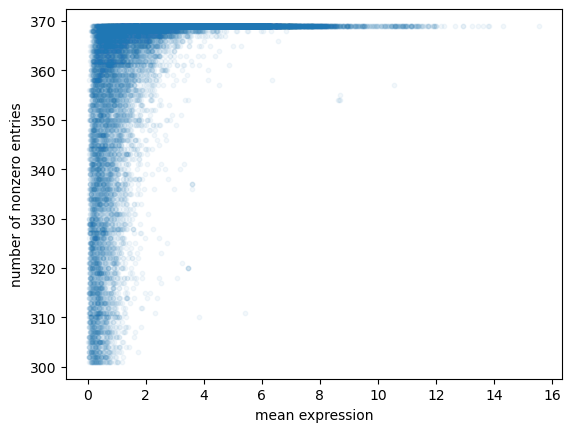

In [53]:
x = transcriptomics_nonzero_filtered.mean()
z = transcriptomics_nonzero_filtered.var()
y = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

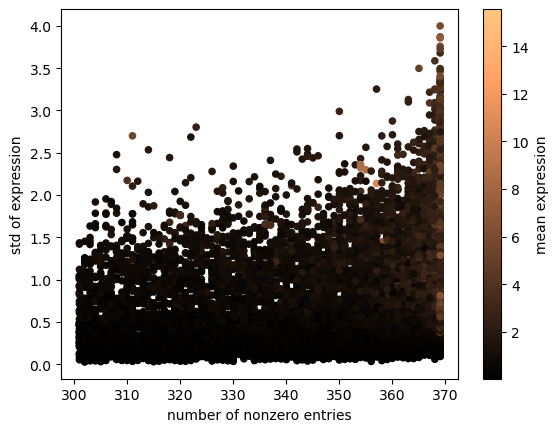

In [54]:
z = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.std()
x = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

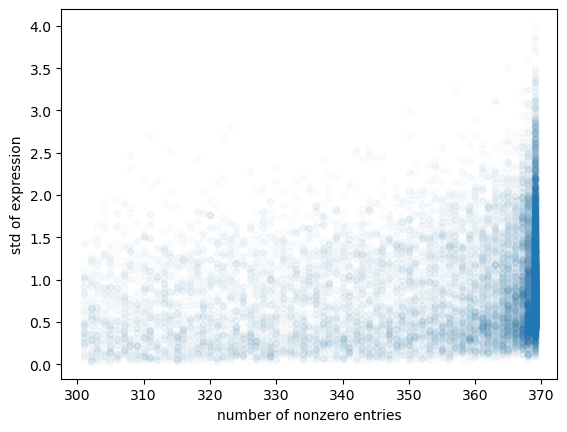

In [55]:
z = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.std()
x = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=20, alpha=0.02)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

## Gaussian Mixtures on Means distribution

In [56]:
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture

In [57]:
gmm = BayesianGaussianMixture(n_components=2,
                              random_state=18).fit(transcriptomics.mean().values.reshape(-1,1))

In [58]:
gmm.means_

array([[0.03445122],
       [2.37607234]])

In [59]:
gmm.covariances_

array([[[2.06248038e-03]],

       [[4.79557590e+00]]])

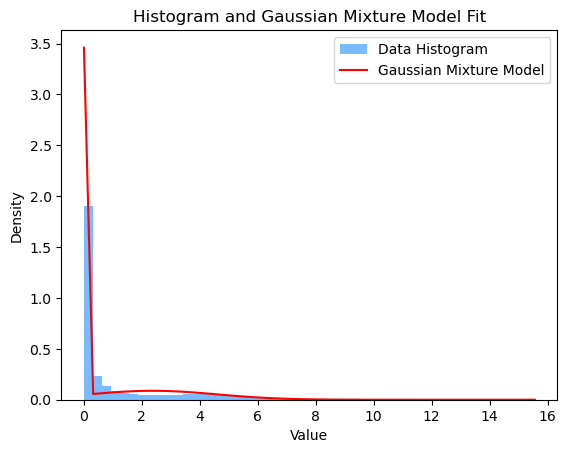

In [60]:
data = transcriptomics.mean()
X = data.values.reshape(-1, 1)

# Get the predicted labels for each data point (optional, for visualizing clusters)
labels = gmm.predict(X)

# Plot the histogram of your data (normalized to form a probability density)
plt.hist(data, bins=50, density=True, alpha=0.6, color='dodgerblue', label='Data Histogram')

# Generate the range of x values for plotting the GMM
x = np.linspace(min(data), max(data), 50).reshape(-1, 1)

# Calculate the probability density for the GMM
logprob = gmm.score_samples(x)  # Log of the probability density
pdf = np.exp(logprob)  # Convert log to the actual probability density

# Plot the Gaussian Mixture Model on top of the histogram
plt.plot(x, pdf, color='r', label='Gaussian Mixture Model')

# Add labels and a legend
plt.legend()
plt.title('Histogram and Gaussian Mixture Model Fit')
plt.xlabel('Value')
plt.ylabel('Density')
plt.show()

## Gaussian Mixtures on the Mean-Variance plane

In [61]:
arr = np.concatenate((transcriptomics.mean().values.reshape(-1,1), transcriptomics.std().values.reshape(-1,1)), axis=1)
gmm = BayesianGaussianMixture(n_components=2,
                              random_state=18).fit(arr)

In [62]:
gmm.means_

array([[0.03286891, 0.09874845],
       [2.33358425, 0.81614276]])

In [63]:
gmm.covariances_

array([[[2.01776518e-03, 3.39405954e-03],
        [3.39405954e-03, 9.78175308e-03]],

       [[4.79895656e+00, 1.46084578e-01],
        [1.46084578e-01, 2.19521719e-01]]])

In [64]:
arr.transpose()[0]

array([2.82520099, 1.83142183, 0.32755518, ..., 6.15178639, 3.54094815,
       4.38776499])

## KDE Local Minimum Filtering

In [67]:
from scipy.stats import gaussian_kde

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


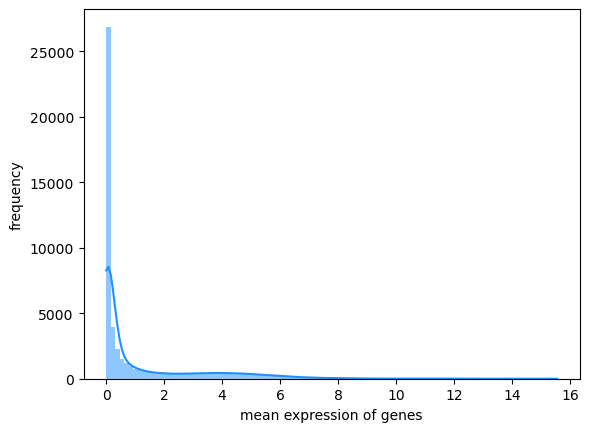

In [68]:
plot_freq(transcriptomics.mean(),
          title='mean expression of genes', bins=100)

In [75]:
data = transcriptomics.mean()

kde = gaussian_kde(data)

x_eval = np.linspace(data.min(), data.max(), 1000)
kde_vals = kde(x_eval)

mean_threshold = None

for i in range(1, len(kde_vals) - 1):
    if kde_vals[i - 1] > kde_vals[i] < kde_vals[i + 1]:
        local_min_x = x_eval[i]
        local_min_y = kde_vals[i]
        print(f"Local minimum at x = {local_min_x:.4f}, KDE = {local_min_y:.4f}")
        if mean_threshold == None:
            mean_threshold = local_min_x

Local minimum at x = 2.4919, KDE = 0.0472
Local minimum at x = 9.9833, KDE = 0.0009
Local minimum at x = 12.5843, KDE = 0.0001
Local minimum at x = 13.2073, KDE = 0.0001
Local minimum at x = 14.9360, KDE = 0.0000


c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


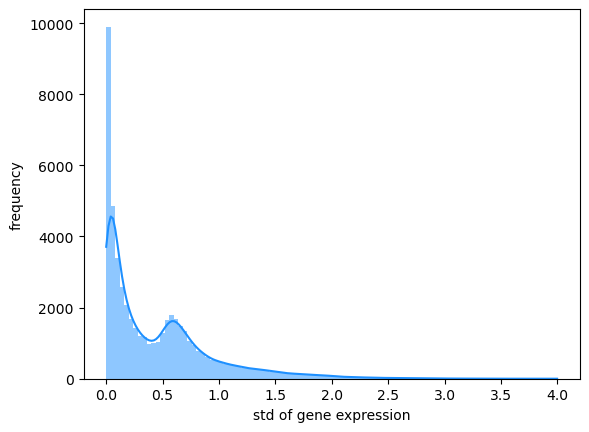

In [91]:
plot_freq(transcriptomics.std(),
          title='std of gene expression', bins=100)

In [89]:
data = transcriptomics.var()

kde = gaussian_kde(data)

x_eval = np.linspace(data.min(), data.max(), 1000)
kde_vals = kde(x_eval)

std_threshold = None

for i in range(1, len(kde_vals) - 1):
    if kde_vals[i - 1] > kde_vals[i] < kde_vals[i + 1]:
        local_min_x = x_eval[i]
        local_min_y = kde_vals[i]
        print(f"Local minimum at x = {local_min_x:.4f}, KDE = {local_min_y:.4f}")
        if std_threshold == None:
            std_threshold = local_min_x

Local minimum at x = 4.5613, KDE = 0.0051
Local minimum at x = 5.1214, KDE = 0.0036
Local minimum at x = 5.4895, KDE = 0.0032
Local minimum at x = 6.3538, KDE = 0.0019
Local minimum at x = 7.0420, KDE = 0.0014
Local minimum at x = 7.3140, KDE = 0.0013
Local minimum at x = 7.7782, KDE = 0.0010
Local minimum at x = 8.0983, KDE = 0.0008
Local minimum at x = 8.9305, KDE = 0.0003
Local minimum at x = 9.4106, KDE = 0.0005
Local minimum at x = 10.1628, KDE = 0.0001
Local minimum at x = 10.8670, KDE = 0.0001
Local minimum at x = 11.7953, KDE = 0.0000
Local minimum at x = 12.5635, KDE = 0.0000
Local minimum at x = 13.2037, KDE = 0.0000
Local minimum at x = 13.7158, KDE = 0.0000
Local minimum at x = 14.0039, KDE = 0.0001
Local minimum at x = 14.5000, KDE = 0.0000
Local minimum at x = 15.4763, KDE = 0.0000


In [77]:
mean_threshold, std_threshold

(2.4919372332230365, 0.40425836678523625)

In [84]:
transcriptomics_kde_filtered = transcriptomics.T[(transcriptomics.mean() >= mean_threshold) |
                                                 (transcriptomics.std() >= std_threshold)].T

In [85]:
transcriptomics.shape

(369, 51989)

In [86]:
transcriptomics_kde_filtered.shape

(369, 22614)

Before filtering:

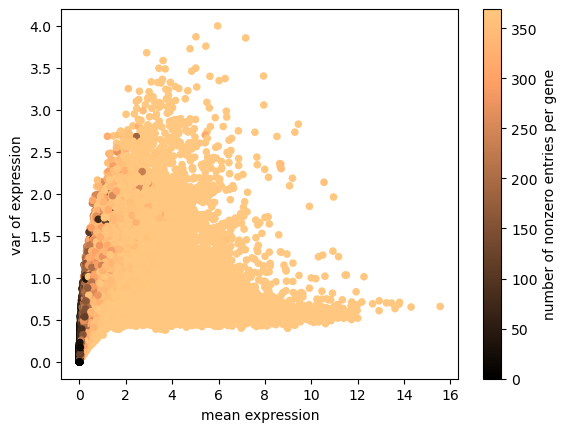

In [97]:
x = transcriptomics.mean()
y = transcriptomics.std()
z = (transcriptomics != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

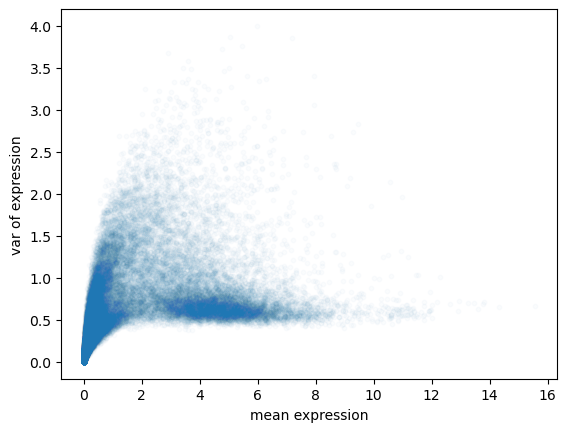

In [101]:
x = transcriptomics.mean()
y = transcriptomics.std()

plt.scatter(x, y, s=10, alpha=0.02)

plt.xlabel('mean expression')
plt.ylabel('var of expression')

plt.show()

After filtering

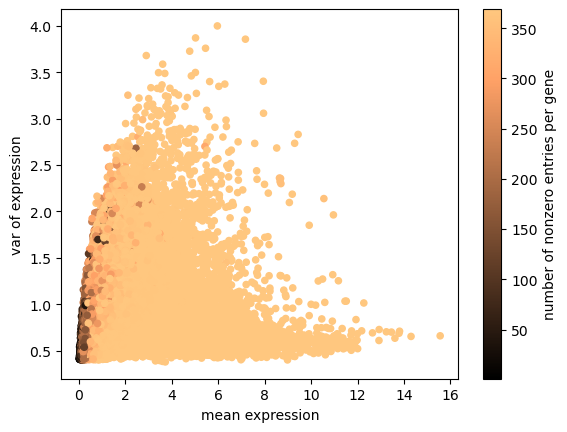

In [95]:
x = transcriptomics_kde_filtered.mean()
y = transcriptomics_kde_filtered.std()
z = (transcriptomics_kde_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

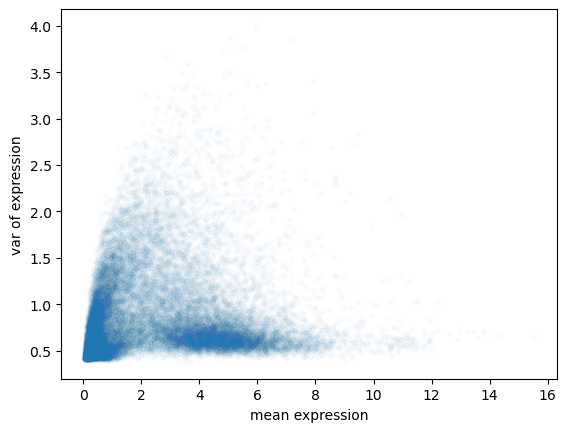

In [100]:
x = transcriptomics_kde_filtered.mean()
y = transcriptomics_kde_filtered.std()

plt.scatter(x, y, s=10, alpha=0.02)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

## Hierarchical Clustering

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans

In [ ]:
linkage_data = linkage(transcriptomics.T, method='ward', metric='euclidean')
dendrogram(linkage_data)

plt.show()

In [ ]:
hierarchical_cluster = AgglomerativeClustering(n_clusters=3, affinity='euclidean', linkage='ward')
labels = hierarchical_cluster.fit_predict(transcriptomics)

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\sklearn\cluster\_agglomerative.py:1005: FutureWarning: Attribute `affinity` was deprecated in version 1.2 and will be removed in 1.4. Use `metric` instead
  warnings.warn(


In [ ]:
len(labels)

369

## K-Means Clustering

In [101]:
kmeans = KMeans(n_clusters=8, random_state=51, n_init="auto").fit(transcriptomics.T)

In [102]:
kmeans.labels_

array([3, 3, 2, ..., 4, 7, 1])

In [103]:
kmeans.labels_.astype(np.float32)

array([3., 3., 2., ..., 4., 7., 1.], dtype=float32)

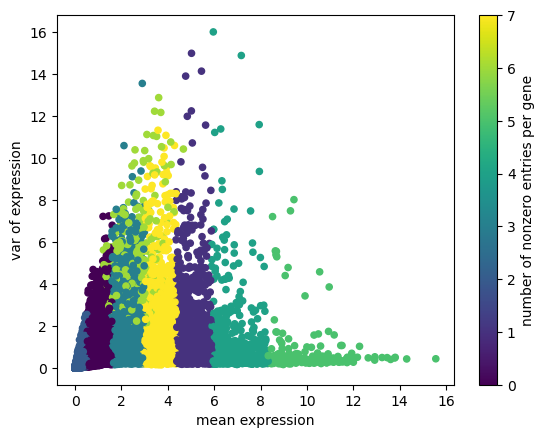

In [104]:
x = transcriptomics.mean()
y = transcriptomics.var()
_ = (transcriptomics != 0).sum()
z = kmeans.labels_.astype(np.float32)

plt.scatter(x, y, c=z, cmap='viridis', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

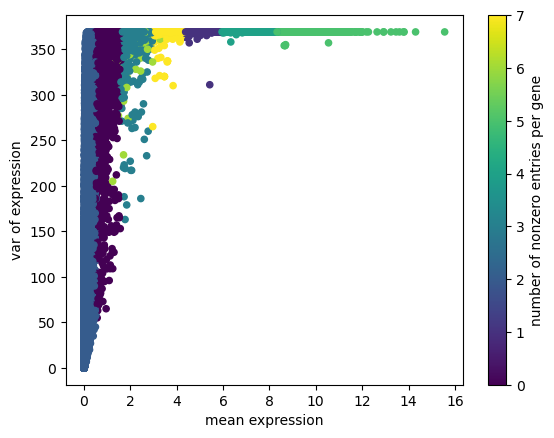

In [105]:
x = transcriptomics.mean()
_ = transcriptomics.std()
y = (transcriptomics != 0).sum()
z = kmeans.labels_.astype(np.float32)

plt.scatter(x, y, c=z, cmap='viridis', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

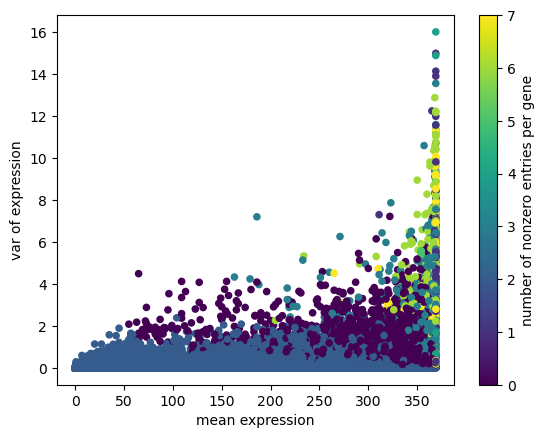

In [106]:
_ = transcriptomics.mean()
y = transcriptomics.var()
x = (transcriptomics != 0).sum()
z = kmeans.labels_.astype(np.float32)

plt.scatter(x, y, c=z, cmap='viridis', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

## Spectral Clustering

In [107]:
from sklearn.cluster import SpectralClustering

In [ ]:
sc = SpectralClustering(n_clusters=2).fit(transcriptomics.T)